# Notebook 02 — Which words do people really search?

**Project:** Searching for Work in Germany: Google Trends Signals of Labour Migration Interest and Policy Effects (focus: migrant care workers)
**Author:** Tayaphon Rodsai · MSc Data Science for Society and Business, Constructor University
**Supervisor:** Prof. Erkan Gunes

---

### The question

Notebook 01 selected **9 origin countries**. Now we need the **search keywords** for each country. The keywords should come from **what people really search**, not from our own guesses (supervisor advice).

### Method: two rounds of related queries ("snowball")

1. **Round 1 (this notebook, done):** for each country, Google Trends lists the **top** and **rising related queries** for the topic *Germany*. We keep only the queries about **work, care, training, language and visa**.
2. **Round 2 (next):** the best keywords from round 1 (plus a few seed words in the local language) are searched again, and **their** related queries give more specific keywords.
3. **Check:** social media and native speakers confirm that the words are really used.

## 1. Setup

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
GT_CHECK = RAW / "gt_check"
ROUND2 = RAW / "gt_keywords" / "round2"
FIGURES = Path("../reports/figures")

CODES = {
    "IN": "India", "TR": "Türkiye", "VN": "Viet Nam", "MA": "Morocco", "TN": "Tunisia",
    "PH": "Philippines", "ID": "Indonesia", "BA": "Bosnia and Herzegovina", "CM": "Cameroon",
}

## 2. Load all round-1 related queries

Source: Google Trends, topic *Germany – Country in Europe*, Jan 2015 – Oct 2026, downloaded 13 Nov 2026 (see Notebook 01). Each country has a **top** list (most searched) and a **rising** list (fastest growing), 50 queries each.

In [2]:
frames = []
for code_, country in CODES.items():
    for list_type in ["top", "rising"]:
        q = pd.read_csv(GT_CHECK / f"{code_}_topic_germany_{list_type}.csv")
        q["code"], q["country"], q["list"] = code_, country, list_type
        frames.append(q)

queries = pd.concat(frames, ignore_index=True)
queries["query"] = queries["query"].astype(str).str.lower().str.strip()
print("Queries loaded:", len(queries), "| unique:", queries["query"].nunique())
queries.head()

Queries loaded: 900 | unique: 629


,query,search interest,increase percent,code,country,list
0,germany,100,0%,IN,India,top
1,german,35,-40%,IN,India,top
2,germany time,12,50%,IN,India,top
3,deutschland,6,140%,IN,India,top
4,time in germany,5,7%,IN,India,top


## 3. Sort queries into themes

Most queries are **noise** for this project (football, time zones, shopping, COVID, even casino and lottery spam). We look for **word stems** that belong to five themes. The stems are written in the languages that appear in the data (English, French, Arabic, Turkish, Vietnamese, Indonesian, Bosnian, German).

| Theme | Meaning | Examples of stems |
|---|---|---|
| **care** | nurse, caregiver | nurse, infirmier, hemşire, điều dưỡng, perawat, medicinska sestra, تمريض |
| **training** | vocational training | ausbildung, du học nghề, التكوين المهني |
| **work** | jobs, salaries, recruitment | job, posao, iş ilan, işçi alımı, emploi, việc làm, kerja, indeed, salaire |
| **language** | learning German | german language, tiếng đức, njemački jezik, almanca, goethe |
| **visa** | migration process | visa, vize, viza, tls, vfs, idata, ambassade, embassy, make it in germany |

A query gets the **first** theme that matches, in the order of the table (so *salaire infirmier* = **care**, not work). **University study** is recorded separately, because it is not a care route (see Notebook 01).

> The automatic sorting is only a **first filter**. Every match is checked by hand (Section 4).

In [3]:
THEMES = {
    "care": ["nurse", "nursing", "caregiver", "infirmier", "infirmière", "aide-soignant", "hemşire", "hasta bakıcı",
             "điều dưỡng", "perawat", "medicinska sestra", "medicinske sestre", "njegovatelj", "تمريض", "ممرض", "pflege",
             "krankenpfleg", "altenpfleg"],
    "training": ["ausbildung", "du học nghề", "التكوين المهني", "formation professionnelle", "mesleki eğitim"],
    "work": ["job", "work in", "working in", "posao", "poslovi", "iş ilan", "işçi alımı", "iş başvuru", "asgari ücret",
             "emploi", "travail", "travailler", "việc làm", "xuất khẩu lao động", "kerja", "indeed", "salaire", "salary", "العمل",
             "maaş", "lương", "gaji", "tuyển", "işkur", "bundesagentur", "azubiyo", "visa sponsorship"],
    "language": ["german language", "learn german", "tiếng đức", "njemački jezik", "njemacki jezik", "učenje njemačkog",
                 "almanca", "bahasa jerman", "goethe", "apprendre l'allemand", "اللغة الالمانية", "اللغة الألمانية",
                 "học tiếng đức", "mit b1", "b1 "],
    "visa": ["visa", "vize", "viza", "vizu", "tls", "vfs", "idata", "ambassade", "ambasada", "embassy", "konsolos",
             "make it in germany", "einreise", "plava karta", "blue card", "chancenkarte", "opportunity card",
             "fırsat kartı", "spajanje porodice"],
    "study (not used)": ["study in", "etudier", "étudier", "du học", "الدراسة", "universit", "ms in germany"],
}


def find_theme(query):
    for theme, stems in THEMES.items():
        if any(stem in query for stem in stems):
            return theme
    return None


queries["theme"] = queries["query"].map(find_theme)
relevant = queries.dropna(subset=["theme"])
print(f"Relevant: {len(relevant)} of {len(queries)} queries ({len(relevant) / len(queries):.0%})")

Relevant: 181 of 900 queries (20%)


### How many relevant queries per country and theme?

In [4]:
overview = pd.crosstab(relevant["country"], relevant["theme"]).reindex(CODES.values()).fillna(0).astype(int)
overview["total"] = overview.sum(axis=1)
overview

theme,care,language,study (not used),training,visa,work,total
country,,,,,,,
India,0,1,3,0,6,1,11
Türkiye,0,0,0,0,15,14,29
Viet Nam,0,1,1,0,1,0,3
Morocco,0,0,2,4,31,1,38
Tunisia,1,0,1,4,41,3,50
Philippines,0,1,0,1,2,0,4
Indonesia,0,0,0,0,0,0,0
Bosnia and Herzegovina,0,3,0,0,19,10,32
Cameroon,0,0,3,0,11,0,14


## 4. The candidate keywords (check by hand)

One row per country and query (a query can appear in both the top and the rising list). Read every row and decide if it really fits.

In [5]:
candidates = (relevant
              .groupby(["country", "theme", "query"], as_index=False)
              .agg(lists=("list", lambda s: " + ".join(sorted(set(s))))))
candidates = candidates.sort_values(["country", "theme", "query"])

pd.set_option("display.max_rows", 200)
candidates

,country,theme,query,lists
0,Bosnia and Herzegovina,language,njemacki jezik,top
1,Bosnia and Herzegovina,language,njemački jezik,top
2,Bosnia and Herzegovina,language,učenje njemačkog,top
3,Bosnia and Herzegovina,visa,ambasada njemacke,rising + top
4,Bosnia and Herzegovina,visa,ambasada njemacke sarajevo,rising
5,Bosnia and Herzegovina,visa,ambasada njemačke,rising + top
6,Bosnia and Herzegovina,visa,einreise deutschland,rising + top
7,Bosnia and Herzegovina,visa,einreise nach deutschland aus bosnien,rising
8,Bosnia and Herzegovina,visa,einreiseanmeldung deutschland,rising
9,Bosnia and Herzegovina,visa,njemacka ambasada,top


> **Finding 1 — useful keywords exist, but they are rare.** Only a small share of the related queries are about work, care, training, language or visa. The rest is mainly football, time zones and shopping.
>
> **Finding 2 — the countries differ a lot.**
> - **Türkiye** and **Bosnia and Herzegovina** have many **work** queries (*almanya iş ilanları*, *posao u njemačkoj*).
> - **Tunisia** has the clearest **care** query (*salaire infirmier en allemagne*) and a **job-seeker visa** query (*visa recherche d'emploi allemagne*), which is close to the Chancenkarte.
> - **Morocco, Tunisia and the Philippines** use the German word **"ausbildung"** directly.
> - **Indonesia** has almost nothing useful (football and lottery), so round 2 is especially important there.
>
> **Finding 3 — some keywords work across countries.** *Make it in Germany* (the official portal), *ausbildung*, and the visa centres (**TLS, VFS, iData**) appear in several countries. Searches for visa appointments are a strong sign of a **real plan** to move.

## 5. Save round 1

In [6]:
candidates.to_csv(PROCESSED / "keywords_round1_candidates.csv", index=False)
print("Saved:", PROCESSED / "keywords_round1_candidates.csv")

Saved: ..\data\processed\keywords_round1_candidates.csv


---
## 6. Round 2 — search the seed keywords

Round 1 found almost **no care keywords**, because the topic *Germany* is too broad (mostly football). In round 2 we searched **specific seed keywords** for each country and theme, and downloaded **their** related queries.

**Settings:** Google Trends · *search term* · whole country · **1 Jan 2015 – 31 Oct 2026** · all categories · web search · downloaded 13 Nov 2026.

| Code | Care | Training | Work |
|---|---|---|---|
| VN | điều dưỡng đức | du học nghề đức | xuất khẩu lao động đức |
| PH | nurse germany | ausbildung in germany | jobs in germany |
| IN | nursing jobs in germany | ausbildung in germany | jobs in germany |
| TR | almanya hemşire | almanya ausbildung | almanya iş ilanları |
| MA | infirmier allemagne | ausbildung allemagne → **ausbildung** (alt) | travail en allemagne → **visa allemagne** (alt) |
| TN | infirmier allemagne | ausbildung allemagne → **ausbildung** (alt) | travail en allemagne → **visa allemagne** (alt) |
| ID | perawat jerman | ausbildung jerman | kerja di jerman |
| BA | medicinska sestra njemačka | ausbildung njemačka | posao u njemačkoj |
| CM | infirmier allemagne | ausbildung allemagne → **ausbildung** (alt) | travailler en allemagne → **visa allemagne** (alt) |

**Alternatives (alt):** the French seeds had almost no data. So we tried the words that people in Morocco, Tunisia and Cameroon **really** used in round 1: *ausbildung* (the German word itself) and *visa allemagne*.

Each search gives three files in `data/raw/gt_keywords/round2/`: the monthly series (`XX_theme.csv`) and the top and rising related queries (`XX_theme_top.csv`, `XX_theme_rising.csv`).

In [7]:
import re

rows = []
for file in sorted(ROUND2.glob("*.csv")):
    m = re.match(r"^([A-Z]{2})_(care|training|work)(_alt\d*)?\.csv$", file.name)
    if not m:
        continue                      # skip the top/rising files here
    code_, theme, alt = m.groups()
    rows.append({"file": file.stem, "code": code_, "country": CODES[code_], "theme": theme,
                 "attempt": "alt" if alt else "main",
                 "keyword": pd.read_csv(file, nrows=0).columns[1]})   # the search word is the column name
seeds = pd.DataFrame(rows)
print("Searches:", len(seeds))
seeds

Searches: 33


,file,code,country,theme,attempt,keyword
0,BA_care,BA,Bosnia and Herzegovina,care,main,medicinska sestra njemačka
1,BA_training,BA,Bosnia and Herzegovina,training,main,ausbildung njemačka
2,BA_work,BA,Bosnia and Herzegovina,work,main,posao u njemačkoj
3,CM_care,CM,Cameroon,care,main,infirmier allemagne
4,CM_training,CM,Cameroon,training,main,ausbildung allemagne
5,CM_training_alt,CM,Cameroon,training,alt,ausbildung
6,CM_work,CM,Cameroon,work,main,travailler en allemagne
7,CM_work_alt,CM,Cameroon,work,alt,visa allemagne
8,ID_care,ID,Indonesia,care,main,perawat jerman
9,ID_training,ID,Indonesia,training,main,ausbildung jerman


## 7. Second Rule 4 check — does each keyword have enough data?

In Notebook 01, the broad topic *Germany* had data in every month. Specific keywords are much rarer. Google shows **0** when a month has too few searches.

**Status of each keyword** (share of zero months, Jan 2015 – Oct 2026):

| Status | Rule | Use |
|---|---|---|
| **strong** | ≤ 10% zero months | whole period |
| **usable** | ≤ 35% zero months | whole period, with care |
| **recent** | more zeros overall, but ≤ 10% zero months **from 2022** | only for the recent period (enough for before/after the 2024 reforms, RQ3) |
| **too rare** | everything else | not used |

The cut-offs (10% and 35%) are our own choice and are reported openly.

In [8]:
series = {}
for _, s in seeds.iterrows():
    data = pd.read_csv(ROUND2 / f"{s['file']}.csv", parse_dates=["Time"], index_col="Time")
    series[s["file"]] = data.iloc[:, 0].replace("<1", 0.5).astype(float)
series = pd.DataFrame(series)


def first_year_with_data(s):
    """First year with at most 2 zero months."""
    zeros_per_year = (s == 0).groupby(s.index.year).sum()
    good = zeros_per_year[zeros_per_year <= 2]
    return int(good.index[0]) if len(good) else None


check = seeds.set_index("file").copy()
check["zero_share_%"] = (series == 0).mean() * 100
check["zero_share_since_2022_%"] = (series.loc["2022":] == 0).mean() * 100
check["data_from"] = series.apply(first_year_with_data)
check["first_nonzero"] = series.apply(lambda s: s[s > 0].index.min().strftime("%Y-%m") if (s > 0).any() else None)


def status(row):
    if row["zero_share_%"] <= 10:
        return "strong"
    if row["zero_share_%"] <= 35:
        return "usable"
    if row["zero_share_since_2022_%"] <= 10:
        return "recent"
    return "too rare"


check["status"] = check.apply(status, axis=1)
check[["country", "theme", "attempt", "keyword", "zero_share_%", "zero_share_since_2022_%", "first_nonzero", "data_from", "status"]].round(0)

,country,theme,attempt,keyword,zero_share_%,zero_share_since_2022_%,first_nonzero,data_from,status
file,,,,,,,,,
BA_care,Bosnia and Herzegovina,care,main,medicinska sestra njemačka,100.0,100.0,NaN,NaN,too rare
BA_training,Bosnia and Herzegovina,training,main,ausbildung njemačka,100.0,100.0,NaN,NaN,too rare
BA_work,Bosnia and Herzegovina,work,main,posao u njemačkoj,25.0,60.0,2015-01,2015.0,usable
CM_care,Cameroon,care,main,infirmier allemagne,95.0,88.0,2023-05,NaN,too rare
CM_training,Cameroon,training,main,ausbildung allemagne,88.0,71.0,2022-10,NaN,too rare
CM_training_alt,Cameroon,training,alt,ausbildung,52.0,0.0,2018-08,2022.0,recent
CM_work,Cameroon,work,main,travailler en allemagne,96.0,91.0,2023-07,NaN,too rare
CM_work_alt,Cameroon,work,alt,visa allemagne,35.0,3.0,2015-07,2022.0,usable
ID_care,Indonesia,care,main,perawat jerman,47.0,0.0,2016-06,2022.0,recent


In [9]:
# Overview: status per country and theme (best attempt)
order = {"strong": 0, "usable": 1, "recent": 2, "too rare": 3}
best = (check.assign(rank=check["status"].map(order))
             .sort_values(["rank", "zero_share_%"])
             .groupby(["country", "theme"]).head(1))
pd.crosstab(best["country"], best["theme"], values=best["status"], aggfunc="first").reindex(CODES.values())

theme,care,training,work
country,,,
India,too rare,recent,strong
Türkiye,usable,recent,strong
Viet Nam,strong,strong,usable
Morocco,too rare,usable,strong
Tunisia,too rare,usable,strong
Philippines,usable,too rare,usable
Indonesia,recent,usable,strong
Bosnia and Herzegovina,too rare,too rare,usable
Cameroon,too rare,recent,usable


> **Finding 4 — specific keywords pass in most countries, but not everywhere.**
> - **Work** keywords have enough data in **all 9 countries** (for Morocco, Tunisia and Cameroon only through *visa allemagne*).
> - **Care** keywords have enough data only in **Viet Nam, the Philippines and Türkiye**, and in **Indonesia** from 2022. In the other countries, the care words are searched too rarely.
> - **Bosnia and Herzegovina** has no care or training keyword with data, but strong **work** searches (*posao u njemačkoj*), which fits its large number of work permits (Notebook 01).
> - **Our own translations often failed; the words found in round 1 worked.** *travail en allemagne* was too rare in Morocco and Tunisia, while *visa allemagne* (seen in round 1) has data in every month.
>
> **Finding 5 — interest in Ausbildung *in Germany* is new.** Searches that combine *Ausbildung* with Germany (*ausbildung in germany*, *almanya ausbildung*, *ausbildung allemagne*) have their **first non-zero month in 2021–2022** in India, the Philippines, Türkiye, Morocco, Tunisia and Cameroon (see `first_nonzero`). Only in Morocco and Tunisia does the single word *ausbildung* have data earlier (from 2018–2019). This is shortly before the 2023–2024 reforms and is important for **RQ3**.

### The best keyword per country and theme over time

Each line is scaled 0–100 **within itself**, so lines show the **shape** over time, not the size. A 3-month average makes the lines easier to read.

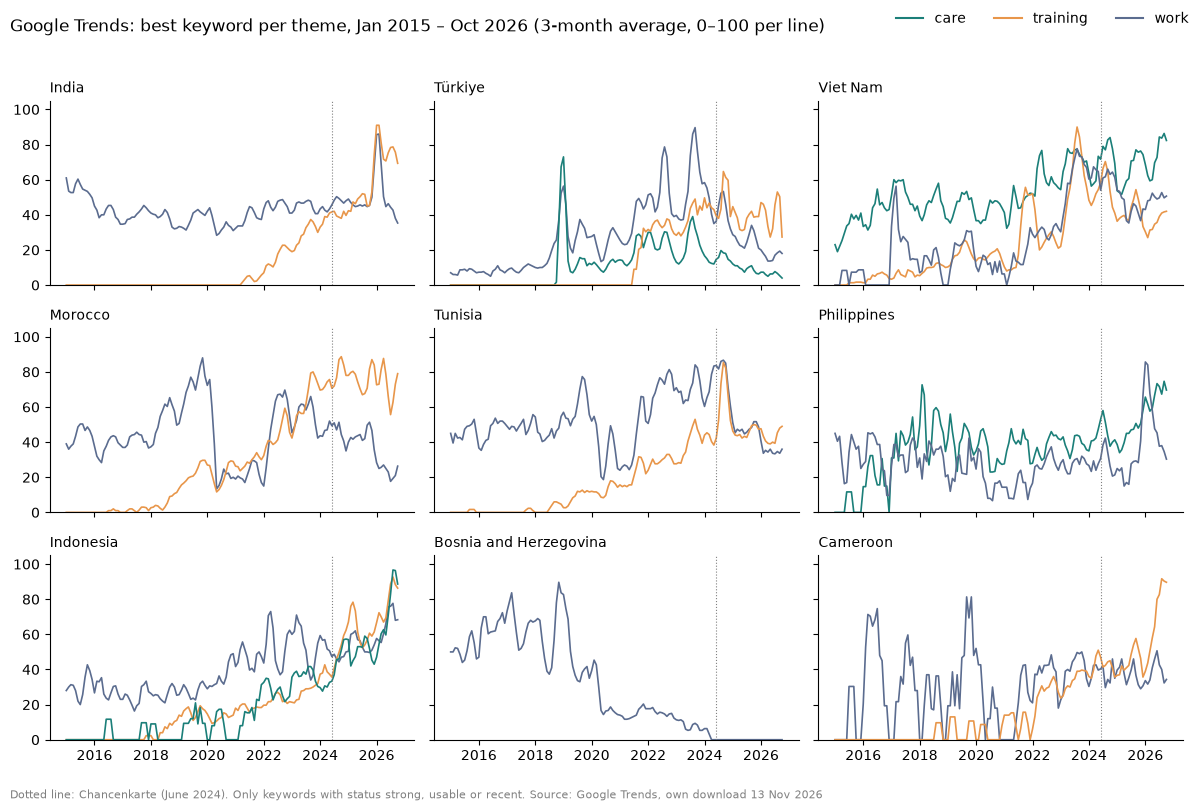

In [10]:
colors = {"care": "#1B7F79", "training": "#E8964A", "work": "#5B6C8F"}
usable = best[best["status"] != "too rare"]

fig, axes = plt.subplots(3, 3, figsize=(12, 8), sharex=True, sharey=True)
for ax, country in zip(axes.flat, CODES.values()):
    for file, row in usable[usable["country"] == country].iterrows():
        ax.plot(series.index, series[file].rolling(3, min_periods=1).mean(),
                color=colors[row["theme"]], linewidth=1.2, label=row["theme"])
    ax.axvline(pd.Timestamp("2024-06-01"), color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(country, fontsize=10, loc="left")
    ax.set_ylim(0, 105)
    ax.spines[["top", "right"]].set_visible(False)

handles = [plt.Line2D([], [], color=c, label=t) for t, c in colors.items()]
fig.legend(handles=handles, loc="upper right", frameon=False, ncol=3)
fig.suptitle("Google Trends: best keyword per theme, Jan 2015 – Oct 2026 (3-month average, 0–100 per line)",
             x=0.01, ha="left", fontsize=12)
plt.tight_layout(rect=(0, 0.03, 1, 0.96))
fig.text(0.01, 0.005, "Dotted line: Chancenkarte (June 2024). Only keywords with status strong, usable or recent. Source: Google Trends, own download 13 Nov 2026",
         fontsize=8, color="grey")
fig.savefig(FIGURES / "02_keywords_by_country.png", dpi=200)
plt.show()

> *This is a first look, not a result. The lines are not comparable between keywords or countries yet (each is 0–100 on its own). Making them comparable is RQ1 (Notebook 04, `gtab`).*

## 8. What do people search together with the seeds?

The related queries of each seed show **which variants people use** and **what they care about**. We sort them into the same themes as in round 1.

In [11]:
frames = []
for file, row in check.iterrows():
    for list_type in ["top", "rising"]:
        path = ROUND2 / f"{file}_{list_type}.csv"
        if path.exists():
            q = pd.read_csv(path)
            q["file"], q["list"] = file, list_type
            frames.append(q)

related = pd.concat(frames, ignore_index=True).merge(
    check[["country", "theme", "keyword"]].rename(columns={"theme": "seed_theme", "keyword": "seed"}),
    left_on="file", right_index=True)
related["query"] = related["query"].astype(str).str.lower().str.strip()
related["theme"] = related["query"].map(find_theme)

print("Related queries:", len(related), "| with a theme:", related["theme"].notna().sum())
pd.crosstab(related["country"], related["theme"]).reindex(CODES.values()).fillna(0).astype(int)

Related queries: 1558 | with a theme: 1231


theme,care,language,study (not used),training,visa,work
country,,,,,,
India,32,9,8,40,5,56
Türkiye,44,1,0,8,5,80
Viet Nam,50,14,22,30,0,28
Morocco,20,0,0,70,86,12
Tunisia,24,0,0,78,91,18
Philippines,71,4,0,25,2,69
Indonesia,6,20,1,34,2,52
Bosnia and Herzegovina,0,0,0,0,0,14
Cameroon,16,2,0,44,30,8


**Note:** for some seeds the **top** and **rising** lists are identical. This happens when **every** related query is *Breakout* (the searches were almost zero before), so Google shows the same list twice. It is not a download error.

In [12]:
identical = [f for f in check.index
             if (ROUND2 / f"{f}_top.csv").exists()
             and (ROUND2 / f"{f}_top.csv").read_bytes() == (ROUND2 / f"{f}_rising.csv").read_bytes()]
print("Top = rising for:", ", ".join(identical))

Top = rising for: CM_care, CM_training, CM_training_alt, CM_work, IN_training, MA_care, MA_training, MA_work, PH_training, TN_training, TR_training


In [13]:
# Care-related queries found in round 2 (the main gap from round 1)
(related[related["theme"] == "care"]
    .drop_duplicates(["country", "query"])
    .sort_values(["country", "search interest"], ascending=[True, False])
    [["country", "seed", "query", "search interest", "increase percent"]])

,country,seed,query,search interest,increase percent
16,Cameroon,infirmier allemagne,salaire infirmier en allemagne,100,Breakout
17,Cameroon,infirmier allemagne,salaire d'un infirmier en allemagne,57,Breakout
27,Cameroon,ausbildung,pflege ausbildung,52,Breakout
28,Cameroon,ausbildung,ausbildung pflege,51,Breakout
31,Cameroon,ausbildung,krankenpfleger ausbildung,22,Breakout
32,Cameroon,ausbildung,ausbildung krankenpfleger,21,Breakout
41,Cameroon,ausbildung,ausbildung zum pflegefachmann,6,Breakout
46,Cameroon,ausbildung,ausbildung pflegefachfrau 2023,4,Breakout
298,India,nursing jobs in germany,nursing salary in germany,100,120%
299,India,nursing jobs in germany,nursing job in germany,91,-10%


> **Finding 6 — care interest is visible through other words.**
> - **Salary** is a key interest in almost every country: *nurse salary in germany* (India, Philippines), *lương điều dưỡng ở đức* (Viet Nam), *almanya hemşire maaşı* (Türkiye), *gaji perawat di jerman* (Indonesia), and *salaire infirmier allemagne* (Morocco, Tunisia, Cameroon).
> - In **Morocco and Cameroon**, care appears inside the **Ausbildung** searches, often in German: *pflege ausbildung*, *krankenpfleger ausbildung*, *ausbildung pflegefachmann*, *ausbildung mit b1*.
> - **Recruitment** words appear: *hemşire alımı almanya* (nurse recruitment, Türkiye), *tuyển điều dưỡng* (Viet Nam), and *işkur almanya iş ilanları* — Türkiye's public employment service lists German jobs.


### Native speaker check (14 Nov 2026)

One native speaker per country was asked three questions: (1) would people search with our keywords, (2) what would *you* type to find a nursing job or nursing training in Germany, and (3) which social media groups or words are used. Answers are kept privately; only the results are reported here.

| Country | Our keywords confirmed? | Extra words suggested | Social media |
|---|---|---|---|
| Türkiye | **Yes**, all four (*almanya iş ilanları*, *almanya hemşire*, *almanya ausbildung*, *almanya hemşire maaşı*) | *almanya hemşire alımı* (recruitment), *almanya hemşire denklik* (recognition of the diploma), *almanya hemşirelik ausbildung*, *Pflegefachfrau Ausbildung*, *B1 B2* | Facebook groups (e.g. *Almanya İş İlanları*, *Almanya Hemşirelik*), hashtags such as #almanyaausbildung #pflegefachkraft |
| Indonesia | **Yes** (*perawat di jerman*, *kerja di jerman*, *ausbildung jerman*, *gaji perawat di jerman*) | *cara menjadi perawat di jerman* (how to become a nurse), *lowongan kerja perawat di jerman* (nurse job vacancies), *ausbildung perawat* | Instagram, Facebook, TikTok (e.g. *Kerja di Jerman*, *Ausbildung Jerman Indonesia*, *Perawat Indonesia di Jerman*) |
| India, Tunisia | *answer pending* | | |
| Viet Nam, Philippines, Morocco, Bosnia and Herzegovina, Cameroon | *not checked by a native speaker* (keywords supported by Google Trends related queries only) | | |

**Why the keywords do not need to change:** in Google Trends, a search term **without quotation marks** counts all searches that contain **all its words, in any order**. So *almanya hemşire* already includes *almanya hemşire alımı* and *almanya hemşire maaşı*, and *perawat jerman* already includes *perawat di jerman* and *gaji perawat di jerman*. The longer phrases the native speakers suggested are therefore **part of** our shorter keywords, which also keeps them frequent enough to have data.

**New ideas for the discussion:** both speakers mention **salary**, **German level (B1/B2)** and **recognition of the diploma** (*denklik*) as key topics — this matches the related queries (Finding 6) and shows what potential migrants worry about.


## 9. The final keyword list

For each country and theme we keep the **best** seed (strong > usable > recent). These keywords are collected and calibrated in Notebooks 03 and 04.

In [14]:
NOTES = {
    "visa allemagne": "visa search used for work; also includes tourist visas",
    "ausbildung": "German word used directly; related queries include nursing training (pflege)",
}

final = usable.reset_index()[["country", "code", "theme", "keyword", "attempt", "status",
                              "zero_share_%", "data_from"]]
final["note"] = final["keyword"].map(NOTES).fillna("")
final = final.sort_values(["country", "theme"]).reset_index(drop=True)
print(f"Final keywords: {len(final)} (from {len(seeds)} searches)")
final.round(0)

Final keywords: 20 (from 33 searches)


,country,code,theme,keyword,attempt,status,zero_share_%,data_from,note
0,Bosnia and Herzegovina,BA,work,posao u njemačkoj,main,usable,25.0,2015.0,
1,Cameroon,CM,training,ausbildung,alt,recent,52.0,2022.0,German word used directly; related queries inc...
2,Cameroon,CM,work,visa allemagne,alt,usable,35.0,2022.0,visa search used for work; also includes touri...
3,India,IN,training,ausbildung in germany,main,recent,54.0,2022.0,
4,India,IN,work,jobs in germany,main,strong,0.0,2015.0,
5,Indonesia,ID,care,perawat jerman,main,recent,47.0,2022.0,
6,Indonesia,ID,training,ausbildung jerman,main,usable,28.0,2019.0,
7,Indonesia,ID,work,kerja di jerman,main,strong,0.0,2015.0,
8,Morocco,MA,training,ausbildung,alt,usable,22.0,2018.0,German word used directly; related queries inc...
9,Morocco,MA,work,visa allemagne,alt,strong,0.0,2015.0,visa search used for work; also includes touri...


In [15]:
# Which country–theme combinations have no keyword?
missing = (pd.MultiIndex.from_product([CODES.values(), ["care", "training", "work"]], names=["country", "theme"])
             .difference(final.set_index(["country", "theme"]).index))
pd.DataFrame(index=missing).reset_index()

,country,theme
0,Bosnia and Herzegovina,care
1,Bosnia and Herzegovina,training
2,Cameroon,care
3,India,care
4,Morocco,care
5,Philippines,training
6,Tunisia,care


## 10. Save round 2

In [16]:
check.to_csv(PROCESSED / "keywords_round2_rule4.csv")
related.to_csv(PROCESSED / "keywords_round2_related.csv", index=False)
final.to_csv(PROCESSED / "keywords_final.csv", index=False)
print("Saved to", PROCESSED.resolve())

Saved to C:\Users\Tayami\Downloads\F26_MDSSB-CAP-01_Capstone Project\data\processed


---
## 11. Summary

**Method.** Two rounds of Google Trends related queries ("snowball"): round 1 from the broad topic *Germany*, round 2 from specific seed keywords per country and theme. Every keyword was checked for enough data (second Rule 4 check).

**Results**
1. Round 1: only about 20% of related queries were relevant; most were football, time zones or shopping.
2. Round 2 found care keywords for **Viet Nam, the Philippines, Türkiye and Indonesia**, and care-related training searches in **Morocco and Cameroon**.
3. **Work** keywords have data in all 9 countries.
4. Searches for **Ausbildung** started around **2021–2022** in six countries.
5. **Salary**, **recruitment** and **visa appointments** are the most common concrete interests.

**Limitations**
- Google shows 0 for months with few searches; several keywords only have data from 2022.
- *visa allemagne* also covers tourist visas.
- Seeds marked as our own translations still need a check by native speakers and on social media.
- Google changed its data collection in **January 2016** and **January 2022** (notes in the Google Trends charts). Jumps at these dates may come from Google, not from people.

**Next steps**
- Check the final keywords on social media and with native speakers.
- **Notebook 03:** collect the final keywords in a consistent way (several samples).
- **Notebook 04:** make them comparable with `gtab` (RQ1).